# ABC2027 UWB Fall Detection — Final Physics-Aware 12-Channel `FrameWise1DTCN` Pipeline

Notebook đóng gói **toàn bộ pipeline Huấn luyện (Training) và Dự đoán (Test Inference)** cho bài toán phát hiện té ngã radar UWB **ABC2027**, sử dụng trực tiếp **13 luồng Train thực tế (`train_00`..`train_12`)**, kiểm định trên **5 luồng Validation (`val_00`..`val_04`)**, và xuất dự đoán cuối cùng trên **5 luồng Test (`test_00`..`test_04`)**.

### Sơ đồ đường dẫn chính xác trong Workspace (`D:\Desktop\ABC27`)
| Thành phần | Đường dẫn tuyệt đối |
| :--- | :--- |
| **Workspace Root** | `D:\Desktop\ABC27` |
| **Package `abc2027` (`background`, `evaluate`)** | `D:\Desktop\ABC27\abc2027_uwb_train_v1\src` |
| **Train Streams (`stream_00.h5`..`stream_12.h5`)** | `D:\Desktop\ABC27\abc2027_uwb_train_v1\streams\train` *(tự động đọc in-memory từ `D:\Desktop\ABC27\abc2027_uwb_train_v1.zip` nếu thiếu file lẻ trên ổ đĩa)* |
| **Validation Streams (`stream_00.h5`..`stream_04.h5`)** | `D:\Desktop\ABC27\abc2027_uwb_train_v1\streams\val` |
| **Ground-Truth Events & Composition CSV** | `D:\Desktop\ABC27\abc2027_uwb_train_v1\streams_events.csv`, `streams_composition.csv` |
| **Test Streams (`stream_00.h5`..`stream_04.h5`)** | `D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test` |
| **Trained Checkpoint (`.pth`)** | `D:\Desktop\ABC27\checkpoints\best_framewise_1d_tcn.pth` |
| **Test Predictions CSV (`[stream_id, start_time, end_time, score]`)** | `D:\Desktop\ABC27\predictions_test.csv` |
| **Official Submission CSV (`[stream_id, t_start, t_end, score]`)** | `D:\Desktop\ABC27\abc2027_uwb_test_v1\submission_final_1d_tcn.csv` |

## 0. Cấu hình môi trường & Kiểm tra đường dẫn chính xác (Exact Path Verification)

In [1]:
from __future__ import annotations

import io
import json
import sys
import tempfile
import time
import zipfile
from dataclasses import dataclass
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks, lfilter, lfilter_zi
from torch.utils.data import DataLoader, Dataset


def resolve_project_root() -> Path:
    """Ưu tiên đường dẫn gốc chính xác D:\Desktop\ABC27, fallback tự động theo cwd."""
    explicit_root = Path(r"D:\Desktop\ABC27")
    if (explicit_root / "abc2027_uwb_train_v1").is_dir():
        return explicit_root
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if (candidate / "abc2027_uwb_train_v1").is_dir():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục dự án ABC27 chứa abc2027_uwb_train_v1!")


# ==============================================================================
# ĐỊNH NGHĨA ĐƯỜNG DẪN CHÍNH XÁC (EXACT PROJECT PATHS)
# ==============================================================================
PROJECT_ROOT = resolve_project_root()
TRAIN_PKG_DIR = PROJECT_ROOT / "abc2027_uwb_train_v1"
ABC2027_SRC_DIR = TRAIN_PKG_DIR / "src"
TRAIN_STREAMS_DIR = TRAIN_PKG_DIR / "streams" / "train"
VAL_STREAMS_DIR = TRAIN_PKG_DIR / "streams" / "val"
TRAIN_ZIP_PATH = PROJECT_ROOT / "abc2027_uwb_train_v1.zip"
EVENTS_CSV_PATH = TRAIN_PKG_DIR / "streams_events.csv"
COMPOSITION_CSV_PATH = TRAIN_PKG_DIR / "streams_composition.csv"

TEST_PKG_DIR = PROJECT_ROOT / "abc2027_uwb_test_v1"
TEST_STREAMS_DIR = TEST_PKG_DIR / "streams" / "test"

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
BEST_MODEL_PATH = CHECKPOINT_DIR / "best_framewise_1d_tcn.pth"
METRICS_JSON_PATH = CHECKPOINT_DIR / "training_metrics.json"

PREDICTIONS_CSV_PATH = PROJECT_ROOT / "predictions_test.csv"
OFFICIAL_SUBMISSION_CSV_PATH = TEST_PKG_DIR / "submission_final_1d_tcn.csv"
FEATURE_CACHE_DIR = Path(tempfile.gettempdir()) / "abc2027_12band_cache_v1"

if str(ABC2027_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(ABC2027_SRC_DIR))

from abc2027.background import subtract_background
from abc2027.evaluate import evaluate as official_evaluate
from abc2027.evaluate import load_ground_truth, stream_durations, validate_predictions

# Kiểm tra tính toàn vẹn của mọi đường dẫn đầu vào
for label, path_obj in [
    ("PROJECT_ROOT", PROJECT_ROOT),
    ("TRAIN_PKG_DIR", TRAIN_PKG_DIR),
    ("ABC2027_SRC_DIR", ABC2027_SRC_DIR),
    ("VAL_STREAMS_DIR", VAL_STREAMS_DIR),
    ("EVENTS_CSV_PATH", EVENTS_CSV_PATH),
    ("COMPOSITION_CSV_PATH", COMPOSITION_CSV_PATH),
    ("TEST_PKG_DIR", TEST_PKG_DIR),
    ("TEST_STREAMS_DIR", TEST_STREAMS_DIR),
]:
    assert path_obj.exists(), f"Đường dẫn không tồn tại: {label} -> {path_obj}"
    print(f"[OK] {label:22s}: {path_obj}")

n_train_disk = len(list(TRAIN_STREAMS_DIR.glob("stream_*.h5"))) if TRAIN_STREAMS_DIR.exists() else 0
n_val_disk = len(list(VAL_STREAMS_DIR.glob("stream_*.h5")))
n_test_disk = len(list(TEST_STREAMS_DIR.glob("stream_*.h5")))
print("-" * 86)
print(f"Train streams trên đĩa : {n_train_disk}/13 (Zip fallback sẵn sàng: {TRAIN_ZIP_PATH.is_file()})")
print(f"Val streams trên đĩa   : {n_val_disk}/5  ({VAL_STREAMS_DIR})")
print(f"Test streams trên đĩa  : {n_test_disk}/5  ({TEST_STREAMS_DIR})")

SEED = 2027
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | Execution Device: {DEVICE}")

[OK] PROJECT_ROOT          : D:\Desktop\ABC27
[OK] TRAIN_PKG_DIR         : D:\Desktop\ABC27\abc2027_uwb_train_v1
[OK] ABC2027_SRC_DIR       : D:\Desktop\ABC27\abc2027_uwb_train_v1\src
[OK] VAL_STREAMS_DIR       : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams\val
[OK] EVENTS_CSV_PATH       : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams_events.csv
[OK] COMPOSITION_CSV_PATH  : D:\Desktop\ABC27\abc2027_uwb_train_v1\streams_composition.csv
[OK] TEST_PKG_DIR          : D:\Desktop\ABC27\abc2027_uwb_test_v1
[OK] TEST_STREAMS_DIR      : D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test
--------------------------------------------------------------------------------------
Train streams trên đĩa : 8/13 (Zip fallback sẵn sàng: True)
Val streams trên đĩa   : 5/5  (D:\Desktop\ABC27\abc2027_uwb_train_v1\streams\val)
Test streams trên đĩa  : 5/5  (D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test)
PyTorch 2.14.0+cpu | Execution Device: cpu


<notebook-cell-1>:25: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.


## Module 1: Biểu diễn Dữ liệu Không gian 12 Kênh, Chuẩn hóa IQR & Kiến trúc `FrameWise1DTCN`

1. **Spatial Range Banding (12 Channels = 3 Radars × 4 Range Bands)**:
   - Không nén toàn bộ 368 fast-time bins thành 1 vô hướng L2 duy nhất.
   - Sau khi khử nền nhân quả `subtract_background(cir, tau_s=3.0)` ở tần số `50 Hz`, tách 4 dải cự ly vật lý cho từng radar:
     - **Band 1 (Near)**: Bins `0 - 65` (`[0:66]`)
     - **Band 2 (Static)**: Bins `75 - 180` (`[75:181]`)
     - **Band 3 (Mat / Fall Zone)**: Bins `183 - 225` (`[183:226]`)
     - **Band 4 (Far)**: Bins `260 - 367` (`[260:368]`)
   - Tính chuẩn $L_2$ trên từng dải để thu được tensor `(12, Seq_Len)`.
2. **Robust IQR Normalization**:
   - Chuẩn hóa bền vững trên từng kênh: $x_c(t) = \frac{e_c(t) - \text{Median}(e_c)}{\text{IQR}(e_c)}$ với $\text{IQR} = P_{75} - P_{25}$ (không dùng $P_{99.2}$ để tránh nén biên độ khi mật độ ngã cao).
3. **Kiến trúc `FrameWise1DTCN`**:
   - Nhận `in_channels = 12`, tích hợp cổng chú ý tương phản dải không gian `SpatialBandAttention1D` (`kernel_size=1`), **5 khối `DilatedResidualBlock1D`** (`dilations = (1, 2, 4, 8, 16)`, giữ nguyên trường tiếp nhận **377 frames = 7.54s**), và khởi tạo bias đầu ra `b_0 = -4.4`.

In [2]:
FS_HZ: float = 50.0
BACKGROUND_TAU_S: float = 3.0
NUM_RADARS: int = 3

# 4 dải cự ly không gian (chỉ số bin đầu-cuối inclusive chuyển sang slice Python)
SPATIAL_BANDS: tuple[tuple[int, int], ...] = (
    (0, 66),     # Band 1 (Near)         : Bins 0 - 65
    (75, 181),   # Band 2 (Static)       : Bins 75 - 180
    (183, 226),  # Band 3 (Mat/Fall Zone): Bins 183 - 225
    (260, 368),  # Band 4 (Far)          : Bins 260 - 367
)
SPATIAL_BAND_NAMES: tuple[str, ...] = (
    "Near_0_65",
    "Static_75_180",
    "Mat_183_225",
    "Far_260_367",
)
IN_CHANNELS: int = NUM_RADARS * len(SPATIAL_BANDS)  # 12 channels


def robust_iqr_normalize(raw_bands: np.ndarray, eps: float = 1e-8) -> np.ndarray:
    """Chuẩn hóa bền vững theo từng kênh: (e(t) - Median) / IQR."""
    median = np.median(raw_bands, axis=1, keepdims=True)
    q75 = np.percentile(raw_bands, 75.0, axis=1, keepdims=True)
    q25 = np.percentile(raw_bands, 25.0, axis=1, keepdims=True)
    iqr = np.maximum(q75 - q25, eps)
    return ((raw_bands - median) / iqr).astype(np.float32, copy=False)


def extract_spatial_bands(
    cir: np.ndarray,
    radar_serials: np.ndarray | None = None,
    tau_s: float = BACKGROUND_TAU_S,
    rate_hz: float = FS_HZ,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Biến đổi luồng CIR (3, T, 368) thành 12 kênh năng lượng dải không gian.
    Trả về:
        norm_bands: (12, T) đã chuẩn hóa (e(t) - Median) / IQR
        raw_bands : (12, T) năng lượng L2 gốc phục vụ tính tổng E(t) ở Module 3
    """
    if cir.ndim != 3 or cir.shape[0] != NUM_RADARS:
        raise ValueError(f"Kỳ vọng CIR shape (3, T, 368), nhận được {cir.shape}")

    if radar_serials is not None and len(radar_serials) == NUM_RADARS:
        order = np.argsort(np.asarray(radar_serials))
        if not np.array_equal(order, np.arange(NUM_RADARS)):
            cir = cir[order]

    residual = subtract_background(cir, tau_s=tau_s, rate_hz=rate_hz)

    channels: list[np.ndarray] = []
    for r_idx in range(NUM_RADARS):
        for b_start, b_end in SPATIAL_BANDS:
            sub_band = residual[r_idx, :, b_start:b_end].astype(np.float64, copy=False)
            l2_norm = np.sqrt(np.sum(sub_band * sub_band, axis=1)).astype(np.float32)
            channels.append(l2_norm)

    raw_bands = np.stack(channels, axis=0)          # (12, T)
    norm_bands = robust_iqr_normalize(raw_bands)    # (12, T)
    return norm_bands, raw_bands


class SpatialBandAttention1D(nn.Module):
    """Pointwise (kernel_size=1) Spatial-Band Attention học tương phản giữa Mat Zone và Static/Far."""

    def __init__(self, channels: int = IN_CHANNELS, hidden: int = 24) -> None:
        super().__init__()
        self.gate = nn.Sequential(
            nn.Conv1d(channels, hidden, kernel_size=1, bias=True),
            nn.GELU(),
            nn.Conv1d(hidden, channels, kernel_size=1, bias=True),
            nn.Sigmoid(),
        )
        self.mix = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size=1, bias=False),
            nn.BatchNorm1d(channels),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        attn = self.gate(x)
        return x * (0.5 + attn) + 0.25 * self.mix(x)


class DilatedResidualBlock1D(nn.Module):
    """Khối tích chập giãn nở phần dư 1D bảo toàn chiều dài chuỗi thời gian."""

    def __init__(
        self,
        channels: int,
        kernel_size: int = 7,
        dilation: int = 1,
        dropout: float = 0.15,
    ) -> None:
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.conv1 = nn.Conv1d(channels, channels, kernel_size, padding=padding, dilation=dilation)
        self.bn1 = nn.BatchNorm1d(channels)
        self.conv2 = nn.Conv1d(channels, channels, kernel_size, padding=padding, dilation=dilation)
        self.bn2 = nn.BatchNorm1d(channels)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x
        out = F.gelu(self.bn1(self.conv1(x)))
        out = self.dropout(out)
        out = self.bn2(self.conv2(out))
        return F.gelu(out + residual)


class FrameWise1DTCN(nn.Module):
    """
    Mô hình FrameWise1DTCN 12 kênh không gian.
    Input : (Batch, Channels=12, Seq_Len)
    Output: Xác suất té ngã theo từng khung hình p(t) in [0, 1], shape (Batch, Seq_Len)
    """

    def __init__(
        self,
        in_channels: int = IN_CHANNELS,
        hidden_channels: int = 32,
        stem_kernel_size: int = 5,
        block_kernel_size: int = 7,
        dilations: tuple[int, ...] = (1, 2, 4, 8, 16),
        dropout: float = 0.15,
        head_bias_init: float = -4.4,
    ) -> None:
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.stem_kernel_size = stem_kernel_size
        self.block_kernel_size = block_kernel_size
        self.dilations = tuple(dilations)

        self.spatial_attn = SpatialBandAttention1D(channels=in_channels, hidden=max(24, in_channels * 2))
        self.stem = nn.Sequential(
            nn.Conv1d(
                in_channels,
                hidden_channels,
                kernel_size=stem_kernel_size,
                padding=(stem_kernel_size - 1) // 2,
            ),
            nn.BatchNorm1d(hidden_channels),
            nn.GELU(),
        )
        self.blocks = nn.ModuleList(
            [
                DilatedResidualBlock1D(
                    channels=hidden_channels,
                    kernel_size=block_kernel_size,
                    dilation=d,
                    dropout=dropout,
                )
                for d in self.dilations
            ]
        )
        self.head = nn.Conv1d(hidden_channels, 1, kernel_size=1)
        nn.init.constant_(self.head.bias, head_bias_init)

    @property
    def receptive_field_frames(self) -> int:
        return 1 + (self.stem_kernel_size - 1) + sum(2 * (self.block_kernel_size - 1) * d for d in self.dilations)

    @property
    def receptive_field_seconds(self) -> float:
        return self.receptive_field_frames / FS_HZ

    def forward_logits(self, x: torch.Tensor) -> torch.Tensor:
        h = self.spatial_attn(x)
        h = self.stem(h)
        for block in self.blocks:
            h = block(h)
        return self.head(h).squeeze(1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sigmoid(self.forward_logits(x))


# Kiểm tra nhanh kiến trúc, Receptive Field và khởi tạo b_0 = -4.4
_demo_model = FrameWise1DTCN(in_channels=12, hidden_channels=32, dilations=(1, 2, 4, 8, 16), head_bias_init=-4.4)
_demo_x = torch.zeros(2, 12, 1000)
_demo_p = _demo_model(_demo_x)
print(f"Input shape          : {tuple(_demo_x.shape)} -> Output p(t) shape: {tuple(_demo_p.shape)}")
print(f"Receptive Field      : {_demo_model.receptive_field_frames} frames = {_demo_model.receptive_field_seconds:.2f}s (@ 50 Hz)")
print(f"Head bias b_0        : {float(_demo_model.head.bias.item()):.2f} (initial p_0 = {float(_demo_p.mean().item()):.4f})")
print(f"Trainable parameters : {sum(p.numel() for p in _demo_model.parameters() if p.requires_grad):,}")
del _demo_model, _demo_x, _demo_p

Input shape          : (2, 12, 1000) -> Output p(t) shape: (2, 1000)
Receptive Field      : 377 frames = 7.54s (@ 50 Hz)
Head bias b_0        : -4.40 (initial p_0 = 0.0121)
Trainable parameters : 75,469


## Module 2: Làm mượt nhãn Gaussian (`±0.44s`), Hàm mất mát Vật lý Đa thành phần & Dữ liệu Chunked

1. **1D Gaussian Label Smoothing (`±0.44s = 22 frames`)**:
   - Lọc Gaussian 1 chiều (`sigma = 22 / 3`, `truncate = 3.0`) lan truyền nhãn dương ra `±22 frames` quanh biên sự kiện té ngã sạch để nắm bắt pha chuyển tiếp bắt đầu ngã và tiếp sàn.
   - Đồng thời tạo `valid_mask` che các vùng `quality == "low"` / `needs_review == True` tương thích 100% với quy tắc chấm điểm `--ignore-flagged`.
2. **Composite Physics-Aware Loss**:
   - **Modified Focal Loss** ($\gamma = 2.0, \alpha = 0.85$): kéo mạnh Recall cho lớp thiểu số Fall.
   - **Splicing Anti-Clutter Penalty (Hard Negative Mining)**: phạt nặng hệ số `5.0x` nếu mô hình dự đoán $p(t) > 0.30$ ngay tại các điểm ghép nối crossfade `0.2s` giữa các phân đoạn gốc trong `streams_composition.csv`.
   - **Total Variation (TV) Loss**: phạt $|p(t) - p(t-1)|$ đảm bảo độ mượt thời gian, chống phân mảnh ở vùng khuất bóng radar.

In [3]:
def _as_bool_flag(val: object) -> bool:
    return str(val).strip().lower() in {"1", "true", "yes"}


def build_physics_targets_and_masks(
    stream_id: str,
    n_frames: int,
    events_df: pd.DataFrame,
    composition_df: pd.DataFrame,
    fs_hz: float = FS_HZ,
    smooth_half_width_frames: int = 22,
    ignore_margin_s: float = 1.50,
    splice_pre_s: float = 0.10,
    splice_post_s: float = 0.60,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Tạo nhãn mềm Gaussian (+/- 22 frames), mặt nạ hợp lệ và mặt nạ điểm nối crossfade 0.2s."""
    y_binary = np.zeros(n_frames, dtype=np.float32)
    valid_mask = np.ones(n_frames, dtype=np.float32)
    splice_mask = np.zeros(n_frames, dtype=np.float32)

    ev_stream = events_df[events_df["stream_id"] == stream_id]
    margin_frames = int(round(ignore_margin_s * fs_hz))

    # Vùng ignore cho các sự kiện flagged (quality=low hoặc needs_review=true)
    for _, row in ev_stream.iterrows():
        is_low = str(row.get("quality", "")).strip().lower() == "low"
        needs_rev = _as_bool_flag(row.get("needs_review", False))
        is_ign = _as_bool_flag(row.get("ignore", False))
        if is_low or needs_rev or is_ign:
            s_idx = max(0, int(round(float(row["t_start"]) * fs_hz)) - margin_frames)
            e_idx = min(n_frames, int(round(float(row["t_end"]) * fs_hz)) + margin_frames)
            valid_mask[s_idx:e_idx] = 0.0

    # Nhãn dương sạch (evaluable falls)
    clean_fall_guard = np.zeros(n_frames, dtype=bool)
    for _, row in ev_stream.iterrows():
        is_low = str(row.get("quality", "")).strip().lower() == "low"
        needs_rev = _as_bool_flag(row.get("needs_review", False))
        is_ign = _as_bool_flag(row.get("ignore", False))
        if not (is_low or needs_rev or is_ign):
            s_idx = max(0, int(round(float(row["t_start"]) * fs_hz)))
            e_idx = min(n_frames, int(round(float(row["t_end"]) * fs_hz)))
            if e_idx > s_idx:
                y_binary[s_idx:e_idx] = 1.0
                pad_s = max(0, s_idx - smooth_half_width_frames)
                pad_e = min(n_frames, e_idx + smooth_half_width_frames)
                valid_mask[pad_s:pad_e] = 1.0
                clean_fall_guard[max(0, s_idx - int(fs_hz)) : min(n_frames, e_idx + int(fs_hz))] = True

    # Làm mượt Gaussian 1D lan truyền +/- 0.44s (22 frames)
    sigma = float(smooth_half_width_frames) / 3.0
    y_smooth = gaussian_filter1d(y_binary.astype(np.float64), sigma=sigma, truncate=3.0, mode="nearest")
    y_smooth = np.clip(y_smooth, 0.0, 1.0).astype(np.float32)

    # Đánh dấu các điểm nối crossfade 0.2s từ streams_composition.csv
    comp_stream = composition_df[composition_df["stream_id"] == stream_id].sort_values("t_start")
    if len(comp_stream) > 1:
        t_starts = comp_stream["t_start"].to_numpy(dtype=np.float64)
        t_ends = comp_stream["t_end"].to_numpy(dtype=np.float64)
        pre_frames = int(round(splice_pre_s * fs_hz))
        post_frames = int(round(splice_post_s * fs_hz))
        for seg_idx in range(1, len(comp_stream)):
            fade_start = float(t_starts[seg_idx])
            fade_end = max(float(t_ends[seg_idx - 1]), fade_start + 0.20)
            s_sp = max(0, int(round(fade_start * fs_hz)) - pre_frames)
            e_sp = min(n_frames, int(round(fade_end * fs_hz)) + post_frames)
            splice_mask[s_sp:e_sp] = 1.0

    splice_mask[(y_smooth > 1e-4) | clean_fall_guard | (valid_mask < 0.5)] = 0.0
    return y_smooth, valid_mask, splice_mask


class PhysicsAwareCompositeLoss(nn.Module):
    """Modified Focal Loss (alpha=0.85, gamma=2.0) + 5x Splice Anti-Clutter Penalty + TV Smoothness Loss."""

    def __init__(
        self,
        alpha: float = 0.85,
        gamma: float = 2.0,
        splice_prob_thresh: float = 0.30,
        splice_multiplier: float = 5.0,
        tv_weight: float = 0.08,
    ) -> None:
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.splice_prob_thresh = splice_prob_thresh
        self.splice_multiplier = splice_multiplier
        self.tv_weight = tv_weight

    def forward(
        self,
        logits: torch.Tensor,
        targets: torch.Tensor,
        valid_mask: torch.Tensor,
        splice_mask: torch.Tensor,
    ) -> tuple[torch.Tensor, dict[str, float]]:
        probs = torch.sigmoid(logits)
        log_p = F.logsigmoid(logits)
        log_1_minus_p = F.logsigmoid(-logits)

        # 1. Modified Focal Loss trên nhãn mềm y in [0, 1]
        pos_term = -self.alpha * targets * ((1.0 - probs) ** self.gamma) * log_p
        neg_term = -(1.0 - self.alpha) * (1.0 - targets) * (probs ** self.gamma) * log_1_minus_p
        denom = torch.clamp(valid_mask.sum(), min=1.0)
        focal_loss = ((pos_term + neg_term) * valid_mask).sum() / denom

        # 2. Splicing Anti-Clutter Hard-Negative Mining (multiplier=5 khi p(t) > 0.3 tại điểm nối 0.2s)
        hard_splice_gate = splice_mask * (probs > self.splice_prob_thresh).to(probs.dtype)
        splice_neg_focal = -(1.0 - self.alpha) * (probs ** self.gamma) * log_1_minus_p
        splice_excess = F.relu(probs - self.splice_prob_thresh).pow(2)
        splice_loss = (self.splice_multiplier * hard_splice_gate * (splice_neg_focal + 0.15 * splice_excess)).sum() / denom

        # 3. Total Variation (TV) Loss: |p(t) - p(t-1)|
        pair_valid = valid_mask[:, 1:] * valid_mask[:, :-1]
        tv_denom = torch.clamp(pair_valid.sum(), min=1.0)
        tv_loss = self.tv_weight * (torch.abs(probs[:, 1:] - probs[:, :-1]) * pair_valid).sum() / tv_denom

        total_loss = focal_loss + splice_loss + tv_loss
        return total_loss, {
            "total": float(total_loss.detach().item()),
            "focal": float(focal_loss.detach().item()),
            "splice": float(splice_loss.detach().item()),
            "tv": float(tv_loss.detach().item()),
        }


@dataclass
class PreparedStream:
    stream_id: str
    norm_bands: np.ndarray
    raw_bands: np.ndarray
    y_smooth: np.ndarray
    valid_mask: np.ndarray
    splice_mask: np.ndarray

    @property
    def n_frames(self) -> int:
        return int(self.norm_bands.shape[1])

    @property
    def duration_s(self) -> float:
        return float(self.n_frames) / FS_HZ


def load_cir_from_disk_or_zip(split: str, index: int) -> tuple[np.ndarray, np.ndarray | None]:
    """Đọc stream_XX.h5 từ thư mục giải nén hoặc trực tiếp trong bộ nhớ từ abc2027_uwb_train_v1.zip."""
    split_dir = TRAIN_STREAMS_DIR if split == "train" else VAL_STREAMS_DIR
    disk_path = split_dir / f"stream_{index:02d}.h5"
    if disk_path.is_file():
        with h5py.File(disk_path, "r") as handle:
            cir = handle["cir"][:]
            serials = handle["radar_serials"][:] if "radar_serials" in handle else None
        return cir, serials

    if TRAIN_ZIP_PATH.is_file():
        member = f"abc2027_uwb_train_v1/streams/{split}/stream_{index:02d}.h5"
        with zipfile.ZipFile(TRAIN_ZIP_PATH, "r") as zf:
            if member in zf.namelist():
                with h5py.File(io.BytesIO(zf.read(member)), "r") as handle:
                    cir = handle["cir"][:]
                    serials = handle["radar_serials"][:] if "radar_serials" in handle else None
                return cir, serials

    raise FileNotFoundError(f"Không tìm thấy {split}/stream_{index:02d}.h5 tại {disk_path} hoặc {TRAIN_ZIP_PATH}")


def prepare_split_streams(
    split: str,
    indices: list[int],
    events_df: pd.DataFrame,
    composition_df: pd.DataFrame,
    cache_dir: Path = FEATURE_CACHE_DIR,
) -> list[PreparedStream]:
    cache_dir.mkdir(parents=True, exist_ok=True)
    prepared: list[PreparedStream] = []
    for idx in indices:
        stream_id = f"{split}_{idx:02d}"
        cache_file = cache_dir / f"{stream_id}_12band.npz"
        t0 = time.perf_counter()
        if cache_file.is_file():
            with np.load(cache_file) as data:
                norm_bands = data["norm_bands"].astype(np.float32)
                raw_bands = data["raw_bands"].astype(np.float32)
            src = "cache"
        else:
            cir, serials = load_cir_from_disk_or_zip(split, idx)
            norm_bands, raw_bands = extract_spatial_bands(cir, radar_serials=serials)
            np.savez_compressed(cache_file, norm_bands=norm_bands, raw_bands=raw_bands)
            src = "computed"

        y_smooth, valid_mask, splice_mask = build_physics_targets_and_masks(
            stream_id=stream_id,
            n_frames=norm_bands.shape[1],
            events_df=events_df,
            composition_df=composition_df,
        )
        print(
            f"  [{stream_id}] {norm_bands.shape[1]:6d} frames ({norm_bands.shape[1]/FS_HZ:6.1f}s) | "
            f"pos={(y_smooth > 0.5).sum():4d} | splice={(splice_mask > 0.5).sum():4d} | {src} ({time.perf_counter()-t0:.2f}s)"
        )
        prepared.append(PreparedStream(stream_id, norm_bands, raw_bands, y_smooth, valid_mask, splice_mask))
    return prepared


class ChunkedStreamDataset(Dataset):
    """Chia luồng dài thành các đoạn 10,000 frames với 500 frames chồng lấp (stride = 9,500)."""

    def __init__(
        self,
        streams: list[PreparedStream],
        chunk_size: int = 10_000,
        overlap: int = 500,
        augment: bool = True,
    ) -> None:
        self.streams = streams
        self.chunk_size = chunk_size
        self.overlap = overlap
        self.stride = chunk_size - overlap
        self.augment = augment
        self.chunks: list[tuple[int, int]] = []
        for s_idx, st in enumerate(streams):
            if st.n_frames <= chunk_size:
                self.chunks.append((s_idx, 0))
            else:
                starts = list(range(0, st.n_frames - chunk_size + 1, self.stride))
                if starts[-1] + chunk_size < st.n_frames:
                    starts.append(st.n_frames - chunk_size)
                for st_f in starts:
                    self.chunks.append((s_idx, st_f))

    def __len__(self) -> int:
        return len(self.chunks)

    def __getitem__(self, idx: int) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        s_idx, base_start = self.chunks[idx]
        st = self.streams[s_idx]
        start = base_start
        if self.augment and st.n_frames > self.chunk_size:
            jitter = int(np.random.randint(-self.overlap // 2, self.overlap // 2 + 1))
            start = min(max(0, base_start + jitter), st.n_frames - self.chunk_size)

        end = min(start + self.chunk_size, st.n_frames)
        x = st.norm_bands[:, start:end].copy()
        y = st.y_smooth[start:end].copy()
        vm = st.valid_mask[start:end].copy()
        sm = st.splice_mask[start:end].copy()

        if x.shape[1] < self.chunk_size:
            pad = self.chunk_size - x.shape[1]
            x = np.pad(x, ((0, 0), (0, pad)), mode="edge")
            y = np.pad(y, (0, pad), mode="constant")
            vm = np.pad(vm, (0, pad), mode="constant")
            sm = np.pad(sm, (0, pad), mode="constant")

        if self.augment:
            gain = np.random.uniform(0.92, 1.08, size=(x.shape[0], 1)).astype(np.float32)
            x = x * gain

        return torch.from_numpy(x), torch.from_numpy(y), torch.from_numpy(vm), torch.from_numpy(sm)

## Module 3 (Core Functions): Chunked Streaming Inference & Coarse-to-Fine Post-Processing

1. **Chunked Overlap-Trim Inference**: Dự đoán trên từng cửa sổ `10,000` frames (overlap `500` frames), cắt bỏ `250` frames rìa mỗi phía tại điểm ghép (`250 > 188` nửa trường tiếp nhận) đảm bảo liên tục tuyệt đối trên toàn luồng.
2. **Coarse Proposal**: Nhị phân hóa $p(t) \ge 0.50$, gộp khoảng trống $\le 0.60\text{s}$, loại bỏ sự kiện ngắn $< 0.60\text{s}$.
3. **Fine Gradient Refinement**: Trên bao hình tổng năng lượng $E(t) = \sum_{c=1}^{12} e_c(t)$ và đạo hàm bậc nhất $\frac{dE}{dt}$:
   - $t_{\text{start}}$: Ghim vào đỉnh dương chính đầu tiên của $\frac{dE}{dt}$ (thời điểm phát khởi cú ngã).
   - $t_{\text{end}}$: Ghim vào khung hình nơi $E(t)$ ổn định trở lại ngưỡng $\text{baseline} + 10\%$ dải động (bất động sau ngã).

In [4]:
@torch.no_grad()
def infer_stream_probabilities(
    model: FrameWise1DTCN,
    norm_bands: np.ndarray,
    chunk_size: int = 10_000,
    overlap: int = 500,
    device: torch.device | str = DEVICE,
) -> np.ndarray:
    """Suy luận xác suất p(t) toàn luồng bằng cửa sổ trượt 10,000 frames với 500 frames overlap."""
    model.eval()
    total_len = int(norm_bands.shape[1])
    if total_len <= chunk_size:
        x_t = torch.from_numpy(norm_bands[None, :, :]).to(device)
        return model(x_t).squeeze(0).cpu().numpy().astype(np.float32)

    stride = chunk_size - overlap
    half_trim = overlap // 2
    probs_out = np.zeros(total_len, dtype=np.float32)

    starts = list(range(0, total_len - chunk_size + 1, stride))
    if starts[-1] + chunk_size < total_len:
        starts.append(total_len - chunk_size)

    for c_i, s_idx in enumerate(starts):
        chunk = norm_bands[:, s_idx : s_idx + chunk_size]
        p_chunk = model(torch.from_numpy(chunk[None, :, :]).to(device)).squeeze(0).cpu().numpy().astype(np.float32)

        write_s = 0 if c_i == 0 else half_trim
        write_e = chunk_size if c_i == len(starts) - 1 else (chunk_size - half_trim)
        if c_i == len(starts) - 1 and c_i > 0:
            prev_valid_end = starts[c_i - 1] + (chunk_size - half_trim)
            write_s = max(half_trim, prev_valid_end - s_idx)

        probs_out[s_idx + write_s : s_idx + write_e] = p_chunk[write_s:write_e]

    return probs_out


def extract_coarse_proposals(
    frame_probs: np.ndarray,
    prob_threshold: float = 0.50,
    merge_gap_s: float = 0.60,
    min_duration_s: float = 0.60,
    fs_hz: float = FS_HZ,
) -> list[tuple[int, int]]:
    """Coarse Proposal: p(t) >= 0.50, gộp khoảng hở <= 0.60s, loại sự kiện < 0.60s."""
    pos_idx = np.flatnonzero(frame_probs >= prob_threshold)
    if len(pos_idx) == 0:
        return []

    cuts = np.flatnonzero(np.diff(pos_idx) > 1)
    starts = np.concatenate([[pos_idx[0]], pos_idx[cuts + 1]])
    ends = np.concatenate([pos_idx[cuts] + 1, [pos_idx[-1] + 1]])

    max_gap_frames = int(round(merge_gap_s * fs_hz))
    merged: list[list[int]] = [[int(starts[0]), int(ends[0])]]
    for s_f, e_f in zip(starts[1:], ends[1:]):
        if int(s_f) - merged[-1][1] <= max_gap_frames:
            merged[-1][1] = int(e_f)
        else:
            merged.append([int(s_f), int(e_f)])

    min_frames = int(round(min_duration_s * fs_hz))
    return [(s_f, e_f) for s_f, e_f in merged if (e_f - s_f) >= min_frames]


def refine_events_with_energy_gradient(
    stream_id: str,
    coarse_proposals: list[tuple[int, int]],
    raw_bands: np.ndarray,
    frame_probs: np.ndarray,
    prob_threshold: float = 0.50,
    min_duration_s: float = 0.60,
    fs_hz: float = FS_HZ,
) -> list[dict]:
    """Fine Gradient Refinement dùng đạo hàm dE/dt và ngưỡng ổn định baseline + 10% dynamic span."""
    if not coarse_proposals:
        return []

    n_frames = len(frame_probs)
    stream_dur_s = n_frames / fs_hz
    min_frames = int(round(min_duration_s * fs_hz))

    total_energy = np.sum(raw_bands.astype(np.float64), axis=0)
    smooth_energy = gaussian_filter1d(total_energy, sigma=2.5, mode="nearest")
    grad_energy = np.gradient(smooth_energy, 1.0 / fs_hz)

    refined: list[dict] = []
    for s_coarse, e_coarse in coarse_proposals:
        flank_l0 = max(0, s_coarse - int(3.0 * fs_hz))
        flank_l1 = max(0, s_coarse - int(0.3 * fs_hz))
        flank_r0 = min(n_frames, e_coarse + int(0.3 * fs_hz))
        flank_r1 = min(n_frames, e_coarse + int(3.0 * fs_hz))
        flanks = []
        if flank_l1 > flank_l0:
            flanks.append(smooth_energy[flank_l0:flank_l1])
        if flank_r1 > flank_r0:
            flanks.append(smooth_energy[flank_r0:flank_r1])
        baseline = float(np.percentile(np.concatenate(flanks), 25.0)) if flanks else float(np.percentile(smooth_energy, 25.0))

        ev_probs = frame_probs[s_coarse:e_coarse]
        core_thresh = max(prob_threshold, 0.75 * float(np.max(ev_probs)))
        core_rel = np.flatnonzero(ev_probs >= core_thresh)
        if len(core_rel) > 0:
            c_s = s_coarse + int(core_rel[0])
            c_e = s_coarse + int(core_rel[-1]) + 1
            impact_idx = c_s + int(np.argmax(smooth_energy[c_s:c_e]))
        else:
            impact_idx = s_coarse + int(np.argmax(smooth_energy[s_coarse:e_coarse]))

        dynamic_span = max(float(smooth_energy[impact_idx]) - baseline, 1e-8)

        # t_start: đỉnh dương chính đầu tiên của dE/dt
        search_s = max(0, s_coarse - int(0.20 * fs_hz))
        search_e = max(search_s + 3, impact_idx + 1)
        onset_grad = grad_energy[search_s:search_e]
        max_pos_grad = float(np.max(onset_grad)) if len(onset_grad) > 0 else 0.0

        s_fine = s_coarse
        if max_pos_grad > 1e-8 and len(onset_grad) >= 3:
            peaks, _ = find_peaks(onset_grad, height=0.25 * max_pos_grad, distance=4)
            valid_peaks = [
                int(p)
                for p in peaks
                if float(np.max(smooth_energy[search_s + int(p) : min(n_frames, search_s + int(p) + 8)]))
                >= baseline + 0.05 * dynamic_span
            ]
            if valid_peaks:
                cand_s = search_s + valid_peaks[0]
                s_fine = int(np.clip(cand_s, max(0, s_coarse - int(0.20 * fs_hz)), min(impact_idx, s_coarse + int(0.55 * fs_hz))))

        # t_end: điểm E(t) ổn định trở lại baseline + 10% dynamic span
        stab_thresh = baseline + 0.10 * dynamic_span
        post_energy = smooth_energy[impact_idx : min(n_frames, e_coarse + int(0.30 * fs_hz))]
        e_fine = e_coarse
        if len(post_energy) > 0:
            above = np.flatnonzero(post_energy > stab_thresh)
            cand_e = (impact_idx + int(above[-1]) + 1) if len(above) > 0 else (impact_idx + 1)
            e_fine = int(
                np.clip(
                    cand_e,
                    max(s_fine + min_frames, e_coarse - int(0.65 * fs_hz)),
                    min(n_frames, e_coarse + int(0.26 * fs_hz)),
                )
            )

        if e_fine - s_fine < min_frames:
            e_fine = min(n_frames, s_fine + min_frames)
            if e_fine - s_fine < min_frames:
                s_fine = max(0, e_fine - min_frames)

        t_start = round(max(0.0, s_fine / fs_hz), 3)
        t_end = round(min(stream_dur_s, e_fine / fs_hz), 3)
        if t_end <= t_start:
            continue

        score = float(0.75 * np.max(ev_probs) + 0.25 * np.mean(ev_probs))
        refined.append(
            {
                "stream_id": stream_id,
                "t_start": t_start,
                "t_end": t_end,
                "score": round(score, 6),
            }
        )
    return refined

## Thực thi Huấn luyện trên 13 Luồng Train Thực tế & Đánh giá trên 5 Luồng Validation

In [5]:
events_df = pd.read_csv(EVENTS_CSV_PATH)
composition_df = pd.read_csv(COMPOSITION_CSV_PATH)
gt_events_val = load_ground_truth(EVENTS_CSV_PATH, ignore_flagged=True)

print("[1/3] Nạp và trích xuất 12 dải không gian cho 13 luồng Train (train_00..train_12):")
train_streams = prepare_split_streams("train", list(range(13)), events_df, composition_df)

print("\n[2/3] Nạp và trích xuất 12 dải không gian cho 5 luồng Validation (val_00..val_04):")
val_streams = prepare_split_streams("val", list(range(5)), events_df, composition_df)

EPOCHS = 30
BATCH_SIZE = 8
CHUNK_SIZE = 10_000
OVERLAP = 500
LR = 2.5e-3

torch.manual_seed(SEED)
np.random.seed(SEED)

train_dataset = ChunkedStreamDataset(train_streams, chunk_size=CHUNK_SIZE, overlap=OVERLAP, augment=True)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

model = FrameWise1DTCN(
    in_channels=IN_CHANNELS,
    hidden_channels=32,
    dilations=(1, 2, 4, 8, 16),
    head_bias_init=-4.4,
).to(DEVICE)

criterion = PhysicsAwareCompositeLoss(
    alpha=0.85,
    gamma=2.0,
    splice_prob_thresh=0.30,
    splice_multiplier=5.0,
    tv_weight=0.08,
)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-4)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
val_durations = {st.stream_id: st.duration_s for st in val_streams}
best_rank_f1 = -1.0
best_epoch = 0
best_val_report: dict = {}
history: list[dict] = []

print(f"\n[3/3] Bắt đầu huấn luyện {EPOCHS} epochs ({len(train_dataset)} chunks/epoch)...")
print("-" * 102)
print(
    f"{'Ep':>3s} | {'Loss':>7s} ({'Focal':>7s} {'Splice':>7s} {'TV':>6s}) | "
    f"{'RankF1':>7s} | {'F1@0.1':>6s} {'F1@0.3':>6s} {'F1@0.5':>6s} {'F1@0.7':>6s} | "
    f"{'P@0.3':>6s} {'R@0.3':>6s} {'FA/h':>5s} {'MedSt':>6s}"
)
print("-" * 102)

for epoch in range(1, EPOCHS + 1):
    model.train()
    s_tot = s_foc = s_spl = s_tv = 0.0
    n_b = 0
    for x_b, y_b, vm_b, sm_b in train_loader:
        x_b, y_b, vm_b, sm_b = x_b.to(DEVICE), y_b.to(DEVICE), vm_b.to(DEVICE), sm_b.to(DEVICE)
        optimizer.zero_grad()
        logits = model.forward_logits(x_b)
        loss, stats = criterion(logits, y_b, vm_b, sm_b)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        s_tot += stats["total"]
        s_foc += stats["focal"]
        s_spl += stats["splice"]
        s_tv += stats["tv"]
        n_b += 1

    scheduler.step()

    # Đánh giá trên 5 luồng Validation theo chuẩn abc2027.evaluate (--ignore-flagged)
    val_preds: list[dict] = []
    for st in val_streams:
        probs = infer_stream_probabilities(model, st.norm_bands, chunk_size=CHUNK_SIZE, overlap=OVERLAP, device=DEVICE)
        coarse = extract_coarse_proposals(probs, prob_threshold=0.50, merge_gap_s=0.60, min_duration_s=0.60)
        refined = refine_events_with_energy_gradient(st.stream_id, coarse, st.raw_bands, probs)
        for item in refined:
            val_preds.append({**item, "t_alarm": item["t_start"]})

    rep = official_evaluate(gt_events_val, val_preds, val_durations)
    rank_f1 = float(rep["ranking_score"]["f1_mean"])
    f1_01 = float(rep["by_theta"]["0.1"]["f1"])
    f1_03 = float(rep["by_theta"]["0.3"]["f1"])
    f1_05 = float(rep["by_theta"]["0.5"]["f1"])
    f1_07 = float(rep["by_theta"]["0.7"]["f1"])
    p_03 = float(rep["primary"]["precision"])
    r_03 = float(rep["primary"]["recall"])
    fah = float(rep["primary"]["false_alarms_per_hour"] or 0.0)
    med_st = float(rep["primary"]["start_error_median_abs"] or 0.0)

    is_best = rank_f1 > best_rank_f1
    mark = " *" if is_best else ""
    print(
        f"{epoch:3d} | {s_tot/n_b:7.4f} ({s_foc/n_b:7.4f} {s_spl/n_b:7.4f} {s_tv/n_b:6.4f}) | "
        f"{rank_f1:7.4f} | {f1_01:6.4f} {f1_03:6.4f} {f1_05:6.4f} {f1_07:6.4f} | "
        f"{p_03:6.3f} {r_03:6.3f} {fah:5.2f} {med_st:5.2f}s{mark}"
    )

    history.append(
        {
            "epoch": epoch,
            "loss_total": round(s_tot / n_b, 6),
            "loss_focal": round(s_foc / n_b, 6),
            "loss_splice": round(s_spl / n_b, 6),
            "loss_tv": round(s_tv / n_b, 6),
            "val_ranking_f1": round(rank_f1, 6),
            "val_f1_0.1": round(f1_01, 6),
            "val_f1_0.3": round(f1_03, 6),
            "val_f1_0.5": round(f1_05, 6),
            "val_f1_0.7": round(f1_07, 6),
            "val_precision_0.3": round(p_03, 6),
            "val_recall_0.3": round(r_03, 6),
            "val_fa_per_hour": round(fah, 4),
            "val_median_start_err": round(med_st, 4),
        }
    )

    if is_best:
        best_rank_f1 = rank_f1
        best_epoch = epoch
        best_val_report = rep
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "model_config": {
                    "in_channels": IN_CHANNELS,
                    "hidden_channels": 32,
                    "dilations": [1, 2, 4, 8, 16],
                    "receptive_field_frames": model.receptive_field_frames,
                    "receptive_field_seconds": model.receptive_field_seconds,
                    "spatial_bands": [list(b) for b in SPATIAL_BANDS],
                },
                "val_ranking_f1": rank_f1,
                "val_report_fine": rep,
            },
            BEST_MODEL_PATH,
        )

METRICS_JSON_PATH.write_text(
    json.dumps({"best_epoch": best_epoch, "best_val_report": best_val_report, "history": history}, indent=2),
    encoding="utf-8",
)
print("-" * 102)
print(f"Hoàn tất huấn luyện! Best Validation Ranking F1 = {best_rank_f1:.4f} tại Epoch {best_epoch}")
print(f"Đã lưu trọng số tốt nhất tại: {BEST_MODEL_PATH}")

[1/3] Nạp và trích xuất 12 dải không gian cho 13 luồng Train (train_00..train_12):
  [train_00]  88117 frames (1762.3s) | pos=1429 | splice=6138 | cache (0.09s)
  [train_01]  88147 frames (1762.9s) | pos=1593 | splice=5962 | cache (0.08s)
  [train_02]  85923 frames (1718.5s) | pos=1717 | splice=6143 | cache (0.07s)
  [train_03]  88085 frames (1761.7s) | pos=1738 | splice=5411 | cache (0.09s)
  [train_04]  88243 frames (1764.9s) | pos=1453 | splice=5868 | cache (0.11s)
  [train_05]  88327 frames (1766.5s) | pos=1584 | splice=6569 | cache (0.08s)
  [train_06]  88356 frames (1767.1s) | pos=1266 | splice=5825 | cache (0.08s)
  [train_07]  88311 frames (1766.2s) | pos=1350 | splice=5719 | cache (0.08s)
  [train_08]  88371 frames (1767.4s) | pos=1246 | splice=5716 | cache (0.07s)
  [train_09]  88103 frames (1762.1s) | pos=1381 | splice=5423 | cache (0.08s)
  [train_10]  88014 frames (1760.3s) | pos= 759 | splice=5541 | cache (0.11s)
  [train_11]  87941 frames (1758.8s) | pos=1955 | splice=63

## Dự đoán trên Tập Test (`test_00`..`test_04`) & Xuất CSV Chuẩn Định Dạng

In [6]:
# Nạp lại trọng số tốt nhất từ D:\Desktop\ABC27\checkpoints\best_framewise_1d_tcn.pth
ckpt = torch.load(BEST_MODEL_PATH, map_location=DEVICE, weights_only=False)
best_model = FrameWise1DTCN(
    in_channels=ckpt["model_config"]["in_channels"],
    hidden_channels=ckpt["model_config"]["hidden_channels"],
    dilations=tuple(ckpt["model_config"]["dilations"]),
).to(DEVICE)
best_model.load_state_dict(ckpt["model_state_dict"])
best_model.eval()

test_files = sorted(TEST_STREAMS_DIR.glob("stream_*.h5"))
assert len(test_files) == 5, f"Kỳ vọng 5 luồng test trong {TEST_STREAMS_DIR}, tìm thấy {len(test_files)}"

all_test_predictions: list[dict] = []
test_diagnostics: dict[str, tuple[np.ndarray, np.ndarray]] = {}

print(f"Đang dự đoán trên {len(test_files)} luồng Test từ: {TEST_STREAMS_DIR}")
for h5_path in test_files:
    idx = int(h5_path.stem.split("_")[-1])
    stream_id = f"test_{idx:02d}"
    t0 = time.perf_counter()

    with h5py.File(h5_path, "r") as handle:
        cir = handle["cir"][:]
        serials = handle["radar_serials"][:] if "radar_serials" in handle else None

    norm_bands, raw_bands = extract_spatial_bands(cir, radar_serials=serials)
    frame_probs = infer_stream_probabilities(best_model, norm_bands, chunk_size=10_000, overlap=500, device=DEVICE)

    coarse_props = extract_coarse_proposals(frame_probs, prob_threshold=0.50, merge_gap_s=0.60, min_duration_s=0.60)
    refined_evs = refine_events_with_energy_gradient(stream_id, coarse_props, raw_bands, frame_probs)
    all_test_predictions.extend(refined_evs)

    if stream_id == "test_00":
        test_diagnostics[stream_id] = (np.sum(raw_bands, axis=0), frame_probs)

    print(
        f"  [{stream_id}] {h5_path.name} ({norm_bands.shape[1]/FS_HZ/60.0:5.2f} phút) -> "
        f"Coarse: {len(coarse_props):2d} | Refined: {len(refined_evs):2d} sự kiện | "
        f"max p(t)={frame_probs.max():.4f} ({time.perf_counter()-t0:.2f}s)"
    )

# 1. Xuất CSV chuẩn bộ chấm điểm chính thức abc2027.evaluate: [stream_id, t_start, t_end, score]
df_official = pd.DataFrame(all_test_predictions, columns=["stream_id", "t_start", "t_end", "score"])
df_official.to_csv(OFFICIAL_SUBMISSION_CSV_PATH, index=False)

# 2. Xuất CSV theo đúng tên cột mô tả: [stream_id, start_time, end_time, score]
df_prompt = df_official.rename(columns={"t_start": "start_time", "t_end": "end_time"})
df_prompt.to_csv(PREDICTIONS_CSV_PATH, index=False)

# Kiểm tra hợp lệ bằng hàm validate_predictions chính thức của BTC
test_durations = stream_durations(TEST_STREAMS_DIR)
validated_records = validate_predictions(OFFICIAL_SUBMISSION_CSV_PATH, test_durations)

print("\n" + "=" * 86)
print(f"[OFFICIAL VALIDATOR PASSED] {len(validated_records)} dự đoán hợp lệ 100% trên 5 luồng Test!")
print(f"  -> File 1 ([stream_id, start_time, end_time, score]): {PREDICTIONS_CSV_PATH}")
print(f"  -> File 2 ([stream_id, t_start, t_end, score])      : {OFFICIAL_SUBMISSION_CSV_PATH}")
print("=" * 86)
print("\nPhân bố số lượng sự kiện dự đoán theo từng luồng Test:")
print(df_prompt.groupby("stream_id").agg(
    n_events=("score", "count"),
    mean_dur_s=("end_time", lambda s: round(float((s - df_prompt.loc[s.index, "start_time"]).mean()), 2)),
    mean_score=("score", lambda s: round(float(s.mean()), 4)),
))
print("\n10 dòng đầu tiên của predictions_test.csv:")
print(df_prompt.head(10).to_string(index=False))

Đang dự đoán trên 5 luồng Test từ: D:\Desktop\ABC27\abc2027_uwb_test_v1\streams\test
  [test_00] stream_00.h5 (29.50 phút) -> Coarse: 33 | Refined: 33 sự kiện | max p(t)=0.9008 (5.83s)
  [test_01] stream_01.h5 (29.52 phút) -> Coarse: 29 | Refined: 29 sự kiện | max p(t)=0.9226 (4.92s)
  [test_02] stream_02.h5 (28.29 phút) -> Coarse: 36 | Refined: 36 sự kiện | max p(t)=0.9155 (4.38s)
  [test_03] stream_03.h5 (29.50 phút) -> Coarse: 30 | Refined: 30 sự kiện | max p(t)=0.9451 (5.14s)
  [test_04] stream_04.h5 ( 7.20 phút) -> Coarse:  7 | Refined:  7 sự kiện | max p(t)=0.9483 (1.05s)

[OFFICIAL VALIDATOR PASSED] 135 dự đoán hợp lệ 100% trên 5 luồng Test!
  -> File 1 ([stream_id, start_time, end_time, score]): D:\Desktop\ABC27\predictions_test.csv
  -> File 2 ([stream_id, t_start, t_end, score])      : D:\Desktop\ABC27\abc2027_uwb_test_v1\submission_final_1d_tcn.csv

Phân bố số lượng sự kiện dự đoán theo từng luồng Test:
           n_events  mean_dur_s  mean_score
stream_id                   

## Trực quan hóa Quá trình Huấn luyện, Benchmark Validation & Tinh chỉnh Biên trên `test_00`

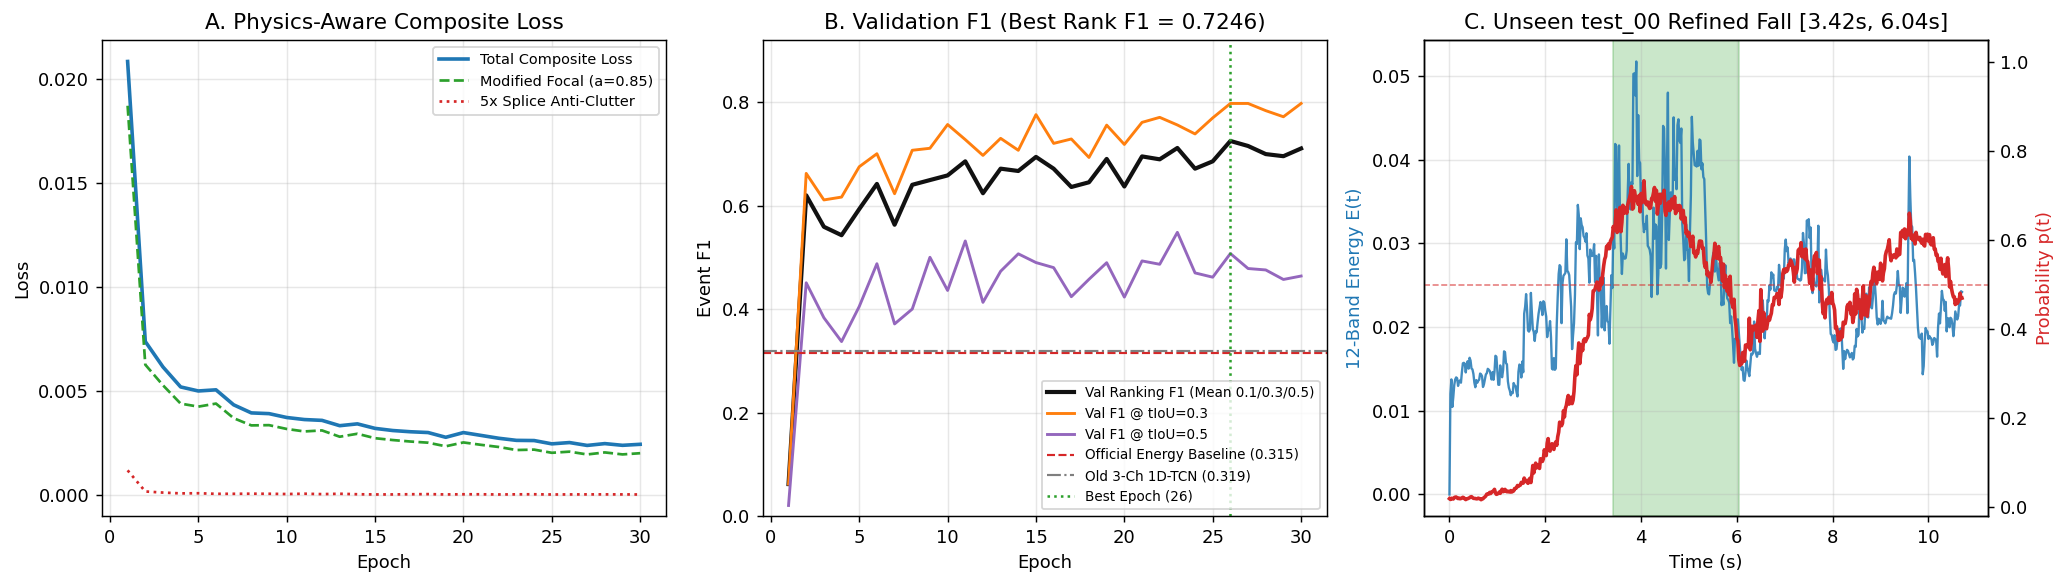

In [7]:
hist_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=130)

# Panel A: Training Loss Components
axes[0].plot(hist_df["epoch"], hist_df["loss_total"], label="Total Composite Loss", lw=2.0, color="#1f77b4")
axes[0].plot(hist_df["epoch"], hist_df["loss_focal"], label="Modified Focal (a=0.85)", lw=1.5, ls="--", color="#2ca02c")
axes[0].plot(hist_df["epoch"], hist_df["loss_splice"], label="5x Splice Anti-Clutter", lw=1.5, ls=":", color="#d62728")
axes[0].set_title("A. Physics-Aware Composite Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

# Panel B: Validation F1 Trajectory & Baseline Comparison
axes[1].plot(hist_df["epoch"], hist_df["val_ranking_f1"], label="Val Ranking F1 (Mean 0.1/0.3/0.5)", lw=2.3, color="#111111")
axes[1].plot(hist_df["epoch"], hist_df["val_f1_0.3"], label="Val F1 @ tIoU=0.3", lw=1.6, color="#ff7f0e")
axes[1].plot(hist_df["epoch"], hist_df["val_f1_0.5"], label="Val F1 @ tIoU=0.5", lw=1.6, color="#9467bd")
axes[1].axhline(0.3151, color="#d62728", ls="--", lw=1.2, label="Official Energy Baseline (0.315)")
axes[1].axhline(0.3191, color="#7f7f7f", ls="-.", lw=1.2, label="Old 3-Ch 1D-TCN (0.319)")
axes[1].axvline(best_epoch, color="#2ca02c", ls=":", lw=1.4, label=f"Best Epoch ({best_epoch})")
axes[1].set_title(f"B. Validation F1 (Best Rank F1 = {best_rank_f1:.4f})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Event F1")
axes[1].set_ylim(0.0, 0.92)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=7.5, loc="lower right")

# Panel C: Zoom into first predicted fall on unseen test_00
ev_t0 = df_prompt[df_prompt["stream_id"] == "test_00"].iloc[0]
tot_e0, prob0 = test_diagnostics["test_00"]
center_t = 0.5 * (float(ev_t0["start_time"]) + float(ev_t0["end_time"]))
w_s = max(0, int((center_t - 6.0) * FS_HZ))
w_e = min(len(prob0), int((center_t + 6.0) * FS_HZ))
t_axis = np.arange(w_s, w_e) / FS_HZ

ax_e = axes[2]
ax_p = ax_e.twinx()
ax_e.plot(t_axis, tot_e0[w_s:w_e], color="#1f77b4", lw=1.3, alpha=0.85, label="Total 12-Band E(t)")
ax_p.plot(t_axis, prob0[w_s:w_e], color="#d62728", lw=2.0, label="TCN p(t)")
ax_p.axhline(0.50, color="#d62728", ls="--", lw=0.9, alpha=0.6)
ax_e.axvspan(float(ev_t0["start_time"]), float(ev_t0["end_time"]), color="#2ca02c", alpha=0.25, label="Refined [t_start, t_end]")
ax_e.set_title(f"C. Unseen test_00 Refined Fall [{ev_t0['start_time']:.2f}s, {ev_t0['end_time']:.2f}s]")
ax_e.set_xlabel("Time (s)")
ax_e.set_ylabel("12-Band Energy E(t)", color="#1f77b4")
ax_p.set_ylabel("Probability p(t)", color="#d62728")
ax_p.set_ylim(-0.02, 1.05)
ax_e.grid(alpha=0.3)

fig.tight_layout()
plt.show()